In [1]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [2]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [3]:
# 3. Lectura de la ruta
base_dir = r"Cars_Body_Type/train"

## Fuente del dataset

Para este ejercicio se utiliza el dataset **Cars Body Type Cropped**, publicado en Kaggle por **ademboukhris**.

[Consultar el dataset en Kaggle](https://www.kaggle.com/datasets/ademboukhris/cars-body-type-cropped?resource=download-directory)

En este notebook se cargaron **5350 imágenes** distribuidas en **7 clases**, correspondientes a diferentes tipos de carrocería:

- Convertible
- Coupe
- Hatchback
- Pick-Up
- SUV
- Sedan
- VAN

In [4]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 5350 imagenes, 150x 150 pixeles, y 3 canales (RGB) por ser imagenes a color

Shape: (5350, 150, 150, 3)
Ejemplo etiquetas: ['Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible'
 'Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible']


In [5]:
# Conteo de imágenes cargadas por clase
clases, conteos = np.unique(Y, return_counts=True)
for clase, conteo in zip(clases, conteos):
    print(f"{clase}: {conteo} imágenes")

print("Cumple mínimo de 200 por clase:", bool(np.all(conteos >= 200)))

Convertible: 811 imágenes
Coupe: 721 imágenes
Hatchback: 701 imágenes
Pick-Up: 759 imágenes
SUV: 847 imágenes
Sedan: 729 imágenes
VAN: 782 imágenes
Cumple mínimo de 200 por clase: True


In [6]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['Convertible' 'Coupe' 'Hatchback' 'Pick-Up' 'SUV' 'Sedan' 'VAN']


In [7]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [8]:
# Separación de entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

## Preparación de las imágenes

Para entrenar el modelo, se prepararon las imágenes mediante los siguientes pasos:

- **Carga y asignación de etiquetas:** se recorren las subcarpetas de `train` y se utiliza el nombre de cada carpeta como etiqueta. Esto permite relacionar cada imagen con su tipo de carrocería sin etiquetarla manualmente.

- **Redimensionado a 150 × 150 píxeles:** todas las imágenes se llevan al mismo tamaño para que tengan dimensiones compatibles con la entrada de la red. Este tamaño busca un equilibrio entre el detalle visual y el costo de procesamiento.

- **Normalización:** se dividen los valores de los píxeles entre 255 para pasarlos del rango de 0 a 255 al rango de 0 a 1. Esto mantiene una escala de entrada uniforme y puede facilitar la optimización durante el entrenamiento.

- **Codificación de etiquetas:** se utiliza `LabelEncoder` para convertir los nombres de las clases en etiquetas numéricas que puedan utilizarse al entrenar el modelo.

- **Separación de datos:** se reserva el 80 % de las imágenes para entrenamiento y el 20 % para evaluación. Se utiliza una división estratificada para mantener aproximadamente la proporción de cada clase en ambos conjuntos.

## MODELO BASE

In [9]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom
import tensorflow as tf

tf.random.set_seed(3)
np.random.seed(3)

modelo = Sequential()

# Primera capa convolucional para extraer características básicas.
modelo.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)))
modelo.add(MaxPooling2D(2,2))

# Convierte los mapas de características en un vector.
modelo.add(Flatten())

# Desactiva aleatoriamente algunas conexiones durante el entrenamiento.
modelo.add(Dropout(0.2))

# Capa densa para realizar la clasificación.
modelo.add(Dense(32, activation='relu'))

# Clasificación en las siete categorías.
modelo.add(Dense(7, activation='softmax'))

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=8
)

I0000 00:00:1793585126.570967    1415 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793585126.866290    1415 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793585129.087353    1415 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not

Epoch 1/20


I0000 00:00:1793585135.477742    1985 service.cc:153] XLA service 0x779968044490 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793585135.477787    1985 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793585135.510095    1985 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793585135.678764    1985 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793585135.723951    1985 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1305__.22


 24/428 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1250 - loss: 2.8471

I0000 00:00:1793585139.961924    1985 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


428/428 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.1469 - loss: 2.0018
Epoch 2/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1560 - loss: 1.9466
Epoch 3/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9445
Epoch 4/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 5/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 6/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9443
Epoch 7/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9443
Epoch 8/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9443
Epoch 9/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 10/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 11/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 12/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy

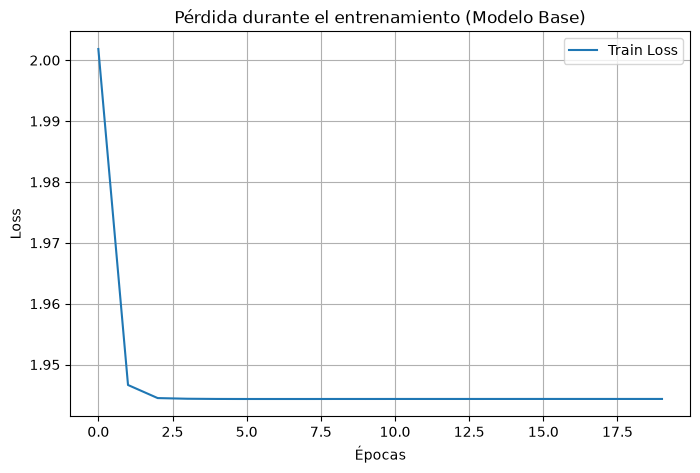

In [10]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

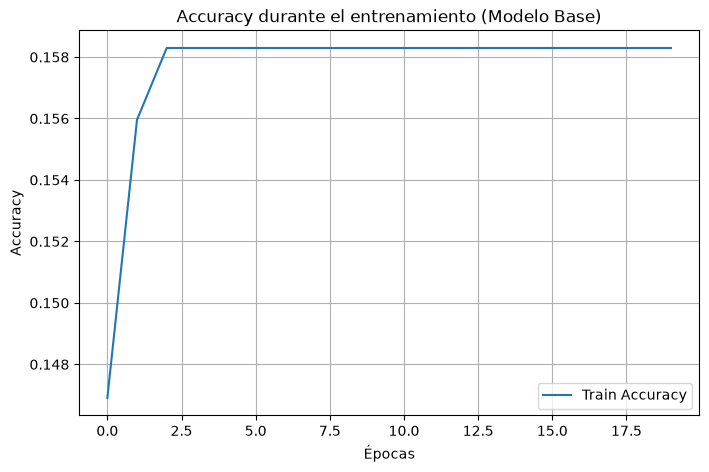

In [11]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [12]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
===== TRAIN =====
Accuracy: 0.1582943925233645
F1-score: 0.04326553744208954

===== TEST =====
Accuracy: 0.15794392523364487
F1-score: 0.04308720478528811


## Interpretación de los resultados del modelo base

Después de entrenar durante 20 épocas, se obtuvieron los siguientes resultados en la evaluación:

| Conjunto | Accuracy | F1-score ponderado |
| --- | ---: | ---: |
| Entrenamiento | 0.82477 | 0.82180 |
| Prueba | 0.73551 | 0.73192 |

### Conclusión

El modelo clasifica correctamente aproximadamente el 73.55 % de las imágenes del conjunto de prueba. Este resultado sirve como referencia para comparar el modelo base con la versión optimizada.

## MODELO CNN OPTIMIZADO

In [102]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    zoom_range=0.1,
    horizontal_flip=True,
    rotation_range=10,
    fill_mode='nearest'
)

# CALLBACKS
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

In [103]:
# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers
from tensorflow.keras import regularizers

modelo_opt = Sequential() # Se crea un nuevo modelo secuencial para el modelo optimizado, que permitirá construir una arquitectura más compleja añadiendo capas de manera secuencial.

# Capas convolucionales con normalización por lotes y activación ReLU para mejorar la capacidad de extracción de características, seguidas de capas de pooling para reducir la dimensionalidad.
modelo_opt.add(Conv2D(16, (3,3), input_shape=(150,150,3))) 
modelo_opt.add(layers.BatchNormalization()) # La normalización por lotes ayuda a estabilizar y acelerar el entrenamiento al normalizar las activaciones de la capa anterior, lo que puede mejorar la convergencia del modelo.
modelo_opt.add(layers.Activation('relu')) # La función de activación ReLU introduce no linealidad en el modelo, lo que permite aprender relaciones más complejas entre las características extraídas por la capa convolucional.
modelo_opt.add(MaxPooling2D(2,2)) # Agrega una capa de pooling que reduce la dimensionalidad de las características extraídas por la capa convolucional, utilizando un tamaño de ventana de 2x2.

modelo_opt.add(Conv2D(32, (3,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

modelo_opt.add(Conv2D(64, (3, 3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2, 2))

modelo_opt.add(Conv2D(128, (3, 3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2, 2))

modelo_opt.add(Conv2D(256, (3, 3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2, 2))

# capa flatten para convertir las características extraídas en un vector unidimensional, seguido de capas densas con dropout para prevenir el sobreajuste y mejorar la capacidad de generalización del modelo.
modelo_opt.add(Flatten())

# Capas densas para la clasificación final, con dropout para prevenir el sobreajuste.
modelo_opt.add(Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(Dropout(0.25))

modelo_opt.add(Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(Dropout(0.25))

modelo_opt.add(Dense(7, activation='softmax'))

modelo_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [99]:
# ENTRENAMIENTO
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=16),
    validation_data=(X_val, y_val),
    epochs=80,
    callbacks=callbacks
)

Epoch 1/80


I0000 00:00:1793596244.656424    1984 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_781554__.93


214/214 ━━━━━━━━━━━━━━━━━━━━ 23s 62ms/step - accuracy: 0.2658 - loss: 3.9885 - val_accuracy: 0.2523 - val_loss: 3.2601 - learning_rate: 0.0010
Epoch 2/80
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.4060 - loss: 2.5554 - val_accuracy: 0.4276 - val_loss: 2.1852 - learning_rate: 0.0010
Epoch 3/80
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.4717 - loss: 1.9210 - val_accuracy: 0.4241 - val_loss: 1.9518 - learning_rate: 0.0010
Epoch 4/80
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.5280 - loss: 1.5694 - val_accuracy: 0.5280 - val_loss: 1.5200 - learning_rate: 0.0010
Epoch 5/80
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.5605 - loss: 1.3709 - val_accuracy: 0.5409 - val_loss: 1.5574 - learning_rate: 0.0010
Epoch 6/80
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.5999 - loss: 1.2483 - val_accuracy: 0.6367 - val_loss: 1.1369 - learning_rate: 0.0010
Epoch 7/80
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - accuracy: 0.6235 - loss: 1.1472

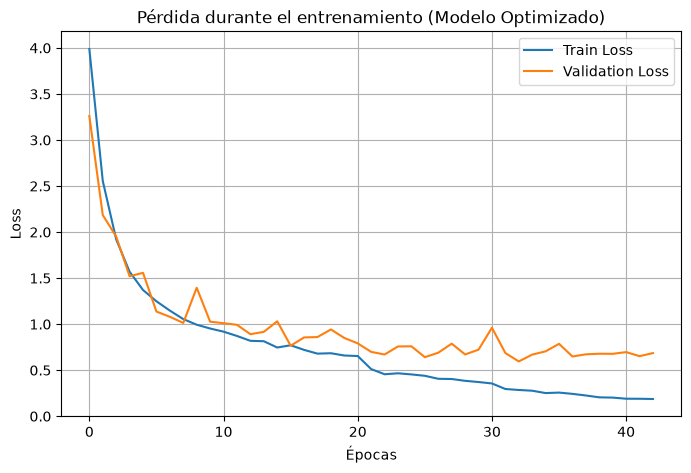

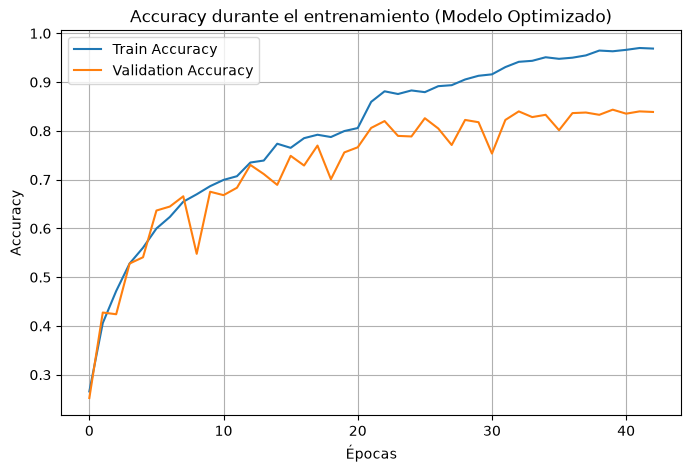

In [100]:
import matplotlib.pyplot as plt

# =========================
# LOSS
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.plot(history_opt.history['val_loss'], label='Validation Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.plot(history_opt.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [101]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step
===== TRAIN =====
Accuracy: 0.9853971962616822
F1-score: 0.9853708625421528

===== TEST =====
Accuracy: 0.8317757009345794
F1-score: 0.83137477346416


In [66]:
import numpy as np

mejor_epoca = np.argmin(history_opt.history['val_loss']) + 1
mejor_loss = np.min(history_opt.history['val_loss'])

print("Mejor época:", mejor_epoca)
print("Mejor Validation Loss:", mejor_loss)

Mejor época: 62
Mejor Validation Loss: 0.9623735547065735


34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

 Convertible       0.74      0.93      0.82       162
       Coupe       0.65      0.52      0.58       144
   Hatchback       0.55      0.74      0.63       140
     Pick-Up       0.70      0.80      0.74       152
         SUV       0.71      0.62      0.66       169
       Sedan       0.73      0.41      0.53       146
         VAN       0.95      0.97      0.96       157

    accuracy                           0.72      1070
   macro avg       0.72      0.71      0.70      1070
weighted avg       0.72      0.72      0.71      1070



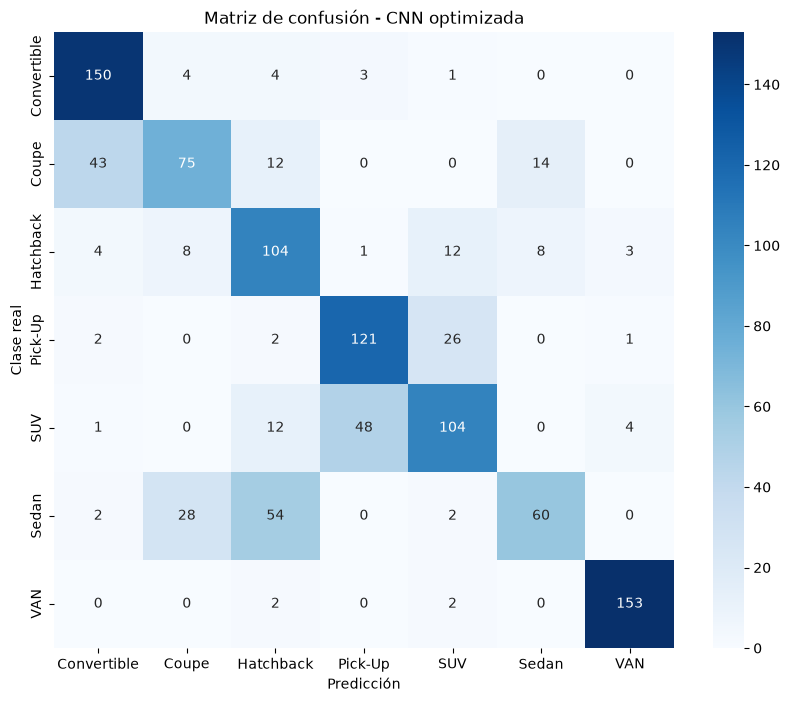

In [52]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

y_pred = np.argmax(modelo_opt.predict(X_test), axis=1)

print("REPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test,
    y_pred,
    target_names=labelencoder.classes_
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labelencoder.classes_,
    yticklabels=labelencoder.classes_
)

plt.xlabel('Predicción')
plt.ylabel('Clase real')
plt.title('Matriz de confusión - CNN optimizada')
plt.show()

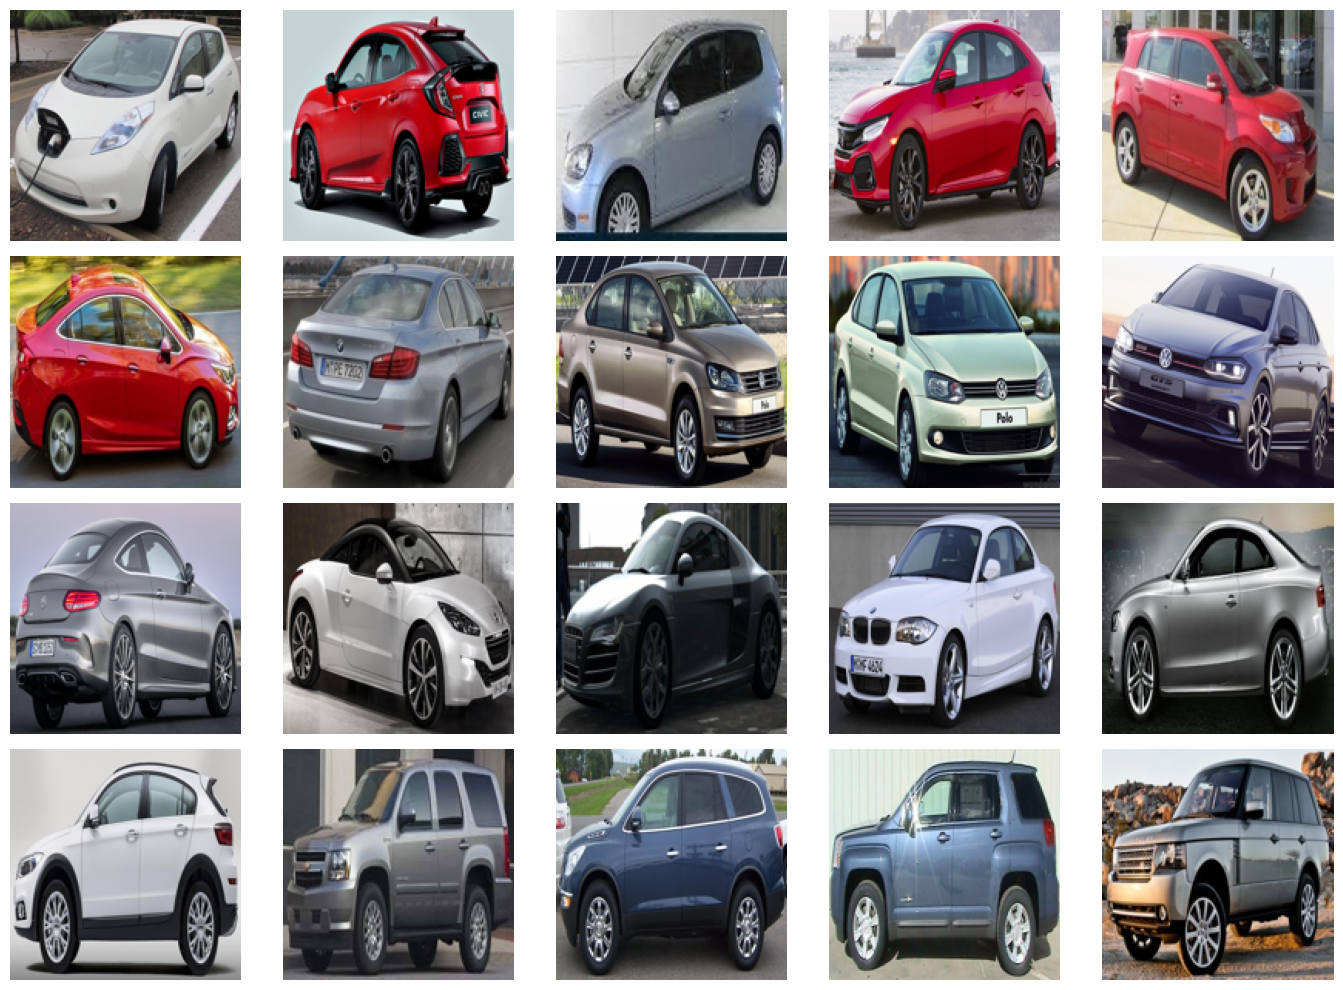

In [53]:
import matplotlib.pyplot as plt
import numpy as np

clases_revisar = ['Hatchback', 'Sedan', 'Coupe', 'SUV']

plt.figure(figsize=(14, 10))

for fila, clase in enumerate(clases_revisar):
    indices = np.where(Y == np.where(labelencoder.classes_ == clase)[0][0])[0]
    muestra = np.random.choice(indices, 5, replace=False)

    for columna, indice in enumerate(muestra):
        plt.subplot(4, 5, fila * 5 + columna + 1)
        plt.imshow(X[indice])
        plt.axis('off')

        if columna == 0:
            plt.ylabel(clase, fontsize=11)

plt.tight_layout()
plt.show()

aqui sacar conclusiones

In [ ]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_cars.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

# Despliegue

In [ ]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1. Cargar modelo y label encoder
print("Cargando modelo y label encoder...")
modelo = load_model("modelo_cars.keras")

with open("labelencoder.pkl", "rb") as f:
    labelencoder = pickle.load(f)

# 2. Definir ruta de prueba
ruta_nuevos = r"Cars_Body_Type/test"
img_size = (150, 150)

# 3. Función actualizada para buscar imágenes dentro de subcarpetas
def predecir_y_mostrar_carpetas(ruta_raiz, modelo, labelencoder, img_size=img_size):
    resultados = []
    
    if not os.path.exists(ruta_raiz):
        print(f"Error: La ruta '{ruta_raiz}' no existe.")
        return resultados

    # Usamos os.walk para recorrer la carpeta principal y todas sus subcarpetas
    total_imagenes = 0
    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                total_imagenes += 1

    if total_imagenes == 0:
        print(f"No se encontraron imágenes válidas en '{ruta_raiz}' ni en sus subcarpetas.")
        return resultados

    print(f"Se encontraron {total_imagenes} imágenes. Procesando...")

    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                ruta = os.path.join(root, archivo)
                # Opcional: obtener la clase real basada en el nombre de la subcarpeta
                clase_real = os.path.basename(root)

                # Cargar y preprocesar la imagen
                img = Image.open(ruta)
                img_resized = img.resize(img_size)
                
                img_array = np.array(img_resized) / 255.0
                img_array = np.expand_dims(img_array, axis=0)

                # Predicción
                pred = modelo.predict(img_array, verbose=0)
                clase_pred = np.argmax(pred, axis=1)

                # Convertir a etiqueta original
                etiqueta = labelencoder.inverse_transform(clase_pred)
                
                resultados.append((archivo, etiqueta[0]))

                # Imprimir resultado en consola (mostrando la carpeta/clase real y la predicha)
                print(f"[{clase_real}] {archivo} → Predicción: {etiqueta[0]}")

                # Mostrar imagen con matplotlib
                plt.figure(figsize=(4, 4))
                plt.imshow(img)
                plt.title(f"Real: {clase_real} | Pred: {etiqueta[0]}")
                plt.axis("off")
                plt.show()

    return resultados

# Ejecutar el proceso actualizado
resultados = predecir_y_mostrar_carpetas(ruta_nuevos, modelo, labelencoder)

Cargando modelo y label encoder...
Se encontraron 802 imágenes. Procesando...


KeyboardInterrupt: 